# Student Performance Prediction with Linear Regression
**Dataset:** UCI Student Performance (Maths class, 395 students) - https://archive.ics.uci.edu/dataset/320/student+performance
**Goal:** predict the final grade `G3` (0-20) from study time, absences and past failures, and see how much earlier grades (`G1`, `G2`) improve the prediction.

**Workflow:** load data -> explore (EDA) -> choose features -> train Linear Regression -> evaluate (MAE, R²) -> visualise -> summarise.

> **How to use:** Runtime -> Run all. Then read the outputs and complete the *Findings* section at the end with your own numbers.

## 1. Setup and loading the data

In [1]:
import io, os, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

The UCI download is a zip file containing `student-mat.csv` (Maths) and `student-por.csv` (Portuguese). Values are separated by **semicolons**, so we pass `sep=";"` to Pandas.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
FILE = "student-mat.csv"

if not os.path.exists(FILE):
    raw = urllib.request.urlopen(URL, timeout=60).read()
    z = zipfile.ZipFile(io.BytesIO(raw))
    if FILE not in z.namelist():                 # the zip can contain a nested zip
        for name in z.namelist():
            if name.endswith(".zip"):
                z = zipfile.ZipFile(io.BytesIO(z.read(name)))
                break
    open(FILE, "wb").write(z.read(FILE))

df = pd.read_csv(FILE, sep=";")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Understanding the data (EDA)
Key columns used in this project:

| Column | Meaning |
|---|---|
| `studytime` | weekly study time: 1 = <2h, 2 = 2-5h, 3 = 5-10h, 4 = >10h |
| `absences` | number of school absences |
| `failures` | number of past class failures (values above 3 are recorded as 3) |
| `G1`, `G2` | grades from the 1st and 2nd period (0-20) |
| `G3` | **final grade (target)** (0-20) |

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("\nColumn types:"); print(df.dtypes.value_counts())
df[["studytime", "absences", "failures", "G1", "G2", "G3"]].describe().round(2)

Missing values: 0

Column types:
object    17
int64     16
Name: count, dtype: int64


,studytime,absences,failures,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00
mean,2.04,5.71,0.33,10.91,10.71,10.42
std,0.84,8.00,0.74,3.32,3.76,4.58
min,1.00,0.00,0.00,3.00,0.00,0.00
25%,1.00,0.00,0.00,8.00,9.00,8.00
50%,2.00,4.00,0.00,11.00,11.00,11.00
75%,2.00,8.00,0.00,13.00,13.00,14.00
max,4.00,75.00,3.00,19.00,19.00,20.00


In [4]:
zero = (df.G3 == 0)
print(f"Students with G3 = 0: {zero.sum()} ({zero.mean():.1%})")
print("Their mean G2:", round(df.loc[zero, 'G2'].mean(), 2), "| mean G2 of all others:", round(df.loc[~zero, 'G2'].mean(), 2))

Students with G3 = 0: 38 (9.6%)
Their mean G2: 4.66 | mean G2 of all others: 11.36


**Note:** a group of students has a final grade of exactly 0. These are most likely students who dropped out or skipped the final exam. Their grade does not reflect ability, which makes them hard for any model to predict. This is an important limitation.

### 2.1 Distribution of the target and of absences

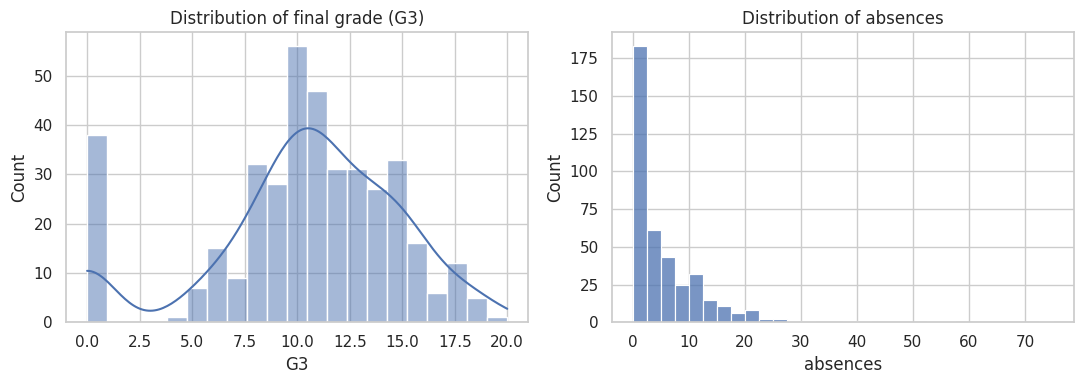

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["G3"], bins=21, kde=True, ax=ax[0]); ax[0].set_title("Distribution of final grade (G3)")
sns.histplot(df["absences"], bins=30, ax=ax[1]);     ax[1].set_title("Distribution of absences")
plt.tight_layout(); plt.show()

### 2.2 Correlation between numeric columns

Correlation runs from -1 to +1. Near +1: move together. Near -1: move in opposite directions. Near 0: little *linear* relationship.

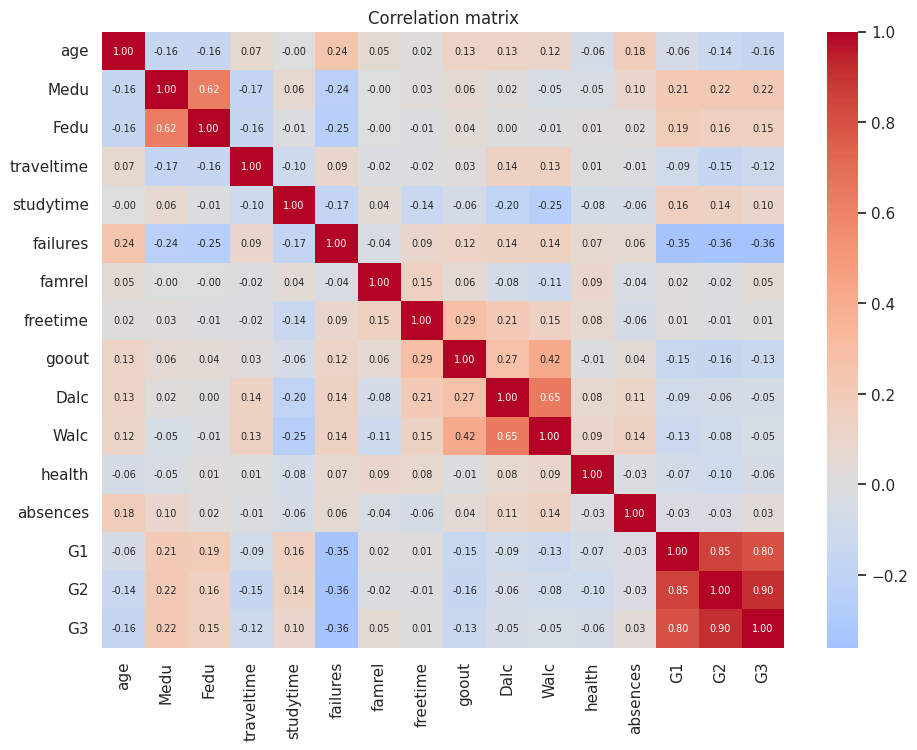

Correlation with G3, strongest first:


,G3
G2,0.90
G1,0.80
failures,-0.36
Medu,0.22
age,-0.16
Fedu,0.15
goout,-0.13
traveltime,-0.12


In [6]:
num = df.select_dtypes("number")
plt.figure(figsize=(11, 8))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix"); plt.show()

print("Correlation with G3, strongest first:")
num.corr()["G3"].drop("G3").sort_values(key=abs, ascending=False).round(2).head(8)

### 2.3 Study time, failures and absences vs final grade

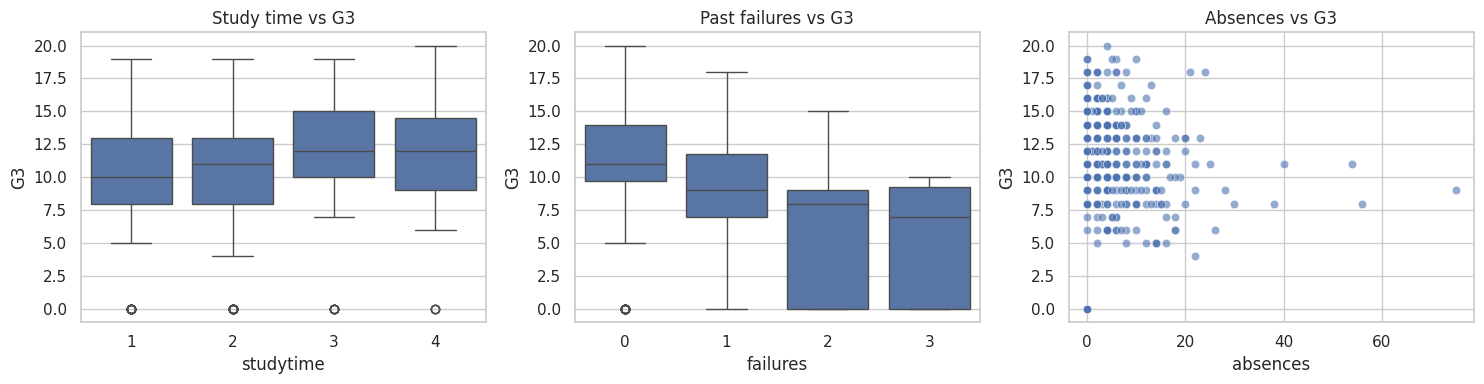

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="studytime", y="G3", ax=ax[0]); ax[0].set_title("Study time vs G3")
sns.boxplot(data=df, x="failures",  y="G3", ax=ax[1]); ax[1].set_title("Past failures vs G3")
sns.scatterplot(data=df, x="absences", y="G3", alpha=0.6, ax=ax[2]); ax[2].set_title("Absences vs G3")
plt.tight_layout(); plt.show()

## 3. Feature selection
We train **two** models so we can see what really drives the prediction:

* **Model A** - the factors named in the task: `studytime`, `absences`, `failures`.
* **Model B** - Model A plus the earlier grades `G1` and `G2`.

`G1` and `G2` are strongly correlated with `G3` (see heatmap), so Model B is expected to be far better. The comparison is the interesting part.

In [8]:
TARGET = "G3"
FEATURES_A = ["studytime", "absences", "failures"]
FEATURES_B = FEATURES_A + ["G1", "G2"]

## 4. Training and 5. Evaluation
* **Train/test split:** 80% of students to train, 20% held back to test on unseen data.
* **MAE** (mean absolute error): average size of the error, in grade points. Lower is better.
* **R²:** share of the variation in grades the model explains. 1 = perfect, 0 = no better than always predicting the average.
* **Baseline:** always predicting the average training grade. A useful model must beat it.
* **5-fold cross-validation:** repeats the train/test process on 5 different splits to check the score is stable.

In [9]:
def evaluate(features, name):
    X, y = df[features], df[TARGET]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

    model = LinearRegression().fit(X_tr, y_tr)          # training
    pred = model.predict(X_te)                          # predictions on unseen students

    mae, r2 = mean_absolute_error(y_te, pred), r2_score(y_te, pred)
    base_mae = mean_absolute_error(y_te, np.full(len(y_te), y_tr.mean()))
    cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")

    print(f"=== {name} ===")
    print(f"Test MAE : {mae:.2f}   (baseline MAE: {base_mae:.2f})")
    print(f"Test R²  : {r2:.3f}")
    print(f"5-fold CV R²: {cv.mean():.3f} +/- {cv.std():.3f}")
    print(f"Intercept: {model.intercept_:.2f}")
    for f, c in zip(features, model.coef_):
        print(f"  coefficient {f:10s}: {c:+.3f}")
    print()
    return dict(name=name, model=model, X_te=X_te, y_te=y_te, pred=pred,
                mae=mae, r2=r2, base_mae=base_mae, cv=cv.mean())

A = evaluate(FEATURES_A, "Model A: study time, absences, failures")
B = evaluate(FEATURES_B, "Model B: Model A + G1 + G2")

=== Model A: study time, absences, failures ===
Test MAE : 3.56   (baseline MAE: 3.65)
Test R²  : 0.031
5-fold CV R²: 0.067 +/- 0.107
Intercept: 9.79
  coefficient studytime : +0.513
  coefficient absences  : +0.041
  coefficient failures  : -2.268

=== Model B: Model A + G1 + G2 ===
Test MAE : 1.34   (baseline MAE: 3.65)
Test R²  : 0.782
5-fold CV R²: 0.812 +/- 0.065
Intercept: -1.62
  coefficient studytime : -0.071
  coefficient absences  : +0.039
  coefficient failures  : -0.456
  coefficient G1        : +0.144
  coefficient G2        : +0.980



In [10]:
summary = pd.DataFrame([{"Model": r["name"], "MAE": round(r["mae"], 2), "Baseline MAE": round(r["base_mae"], 2),
                         "R² (test)": round(r["r2"], 3), "R² (5-fold CV)": round(r["cv"], 3)} for r in (A, B)])
summary

,Model,MAE,Baseline MAE,R² (test),R² (5-fold CV)
0,"Model A: study time, absences, failures",3.56,3.65,0.031,0.067
1,Model B: Model A + G1 + G2,1.34,3.65,0.782,0.812


## 6. Visualising the results

For each model: **actual vs predicted** (points near the red line = good predictions), **residuals** (should scatter randomly around 0), and **coefficients** (how much each feature moves the prediction per +1 unit).

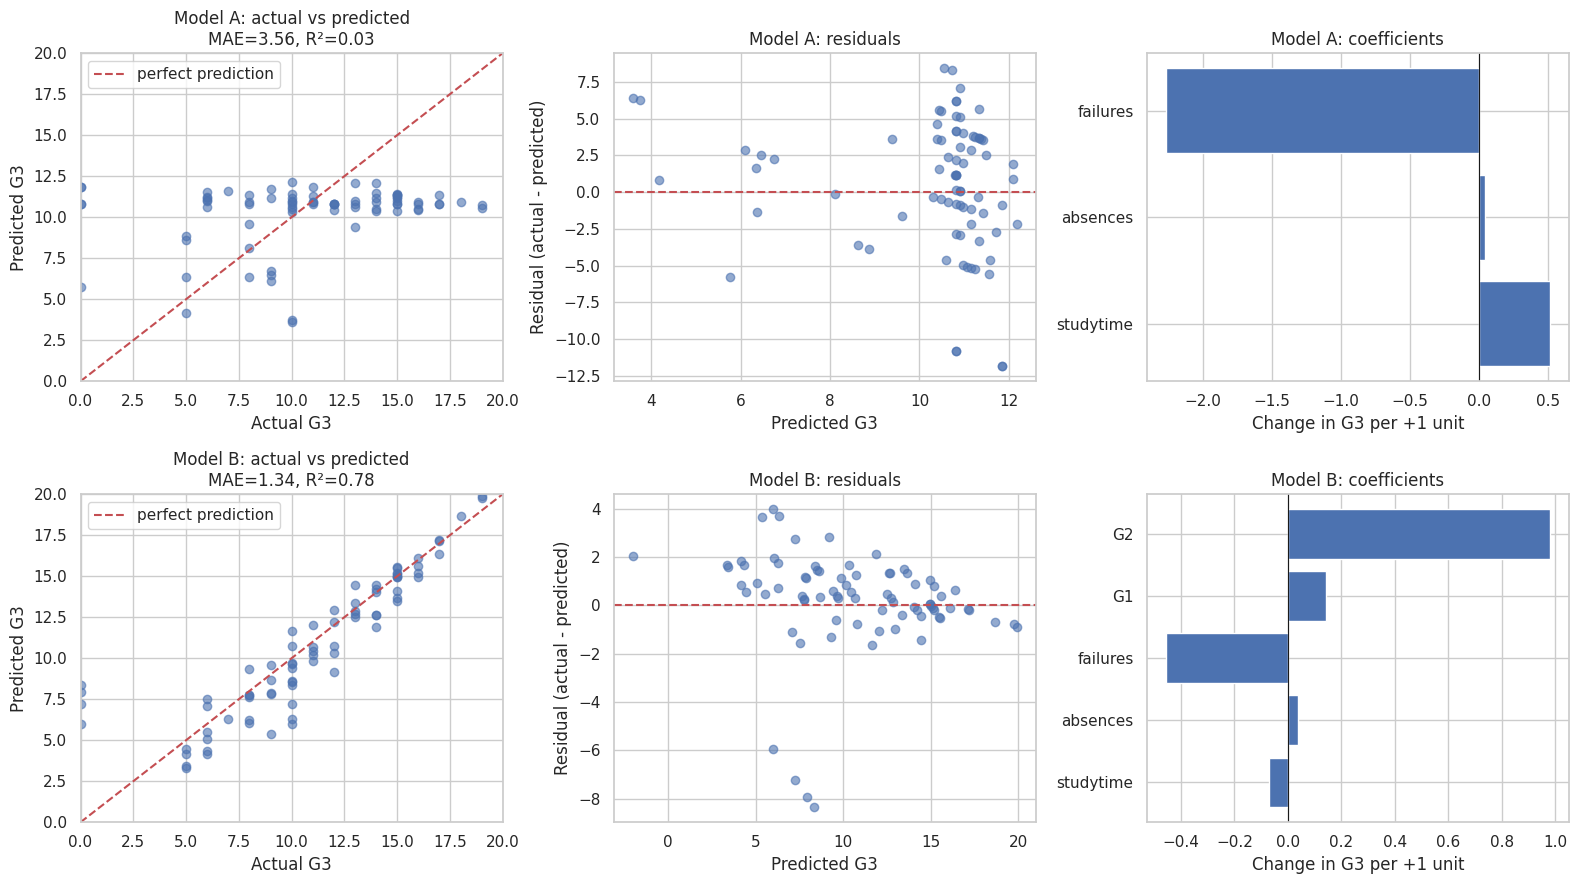

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, r in zip(axes, (A, B)):
    short = r["name"].split(":")[0]
    row[0].scatter(r["y_te"], r["pred"], alpha=0.6)
    row[0].plot([0, 20], [0, 20], "r--", label="perfect prediction")
    row[0].set(xlim=(0, 20), ylim=(0, 20), xlabel="Actual G3", ylabel="Predicted G3",
               title=f"{short}: actual vs predicted\nMAE={r['mae']:.2f}, R²={r['r2']:.2f}")
    row[0].legend()

    row[1].scatter(r["pred"], r["y_te"] - r["pred"], alpha=0.6)
    row[1].axhline(0, color="r", ls="--")
    row[1].set(xlabel="Predicted G3", ylabel="Residual (actual - predicted)", title=f"{short}: residuals")

    row[2].barh(r["X_te"].columns, r["model"].coef_)
    row[2].axvline(0, color="k", lw=0.8)
    row[2].set(xlabel="Change in G3 per +1 unit", title=f"{short}: coefficients")
plt.tight_layout(); plt.show()

### Effect of the dropout (G3 = 0) students
To see how much the zero grades hurt, we check the errors for students with and without G3 = 0 in Model B's test set.

In [12]:
err = (B["y_te"] - B["pred"]).abs()
z = (B["y_te"] == 0)
print(f"Model B MAE, students with G3 = 0   : {err[z].mean():.2f}  (n={z.sum()})")
print(f"Model B MAE, students with G3 > 0   : {err[~z].mean():.2f}  (n={(~z).sum()})")

Model B MAE, students with G3 = 0   : 6.30  (n=5)
Model B MAE, students with G3 > 0   : 1.00  (n=74)


## 7. Summary

### Approach
I loaded the UCI Student Performance data (Maths class), explored it with summary statistics and plots, and predicted the final grade `G3` with Linear Regression. I trained two models: **Model A** with only study time, absences and past failures, and **Model B** which also includes the earlier grades `G1` and `G2`. Both were scored with MAE and R² on a held-out 20% test set, and 5-fold cross-validation checked that the results are stable. A "predict the average" baseline gave a reference point.

### Findings  *(fill in with your numbers from the outputs above)*
* **Model A:** MAE = ___, R² = ___ (baseline MAE = ___). The model is only slightly better than guessing the average, so study time, absences and failures alone explain little of the final grade. `failures` had the clearest effect: each extra past failure changes the predicted grade by about ___ points.
* **Model B:** MAE = ___, R² = ___. Accuracy improves a lot once `G1` and `G2` are included. `G2` has the largest coefficient.
* **Main takeaway:** the best predictor of a student's final grade is their recent grades, not their study habits or attendance. Behaviour data alone gives weak predictions.
* **Dropouts:** the students with G3 = 0 have much larger errors (see the last code cell) and pull the scores down.

### What I learned
* How to load, inspect and summarise data with Pandas, and plot it with Matplotlib/Seaborn.
* Why a model must be tested on data it has not seen (train/test split, cross-validation).
* How to interpret MAE (average error in grade points) and R² (share of variation explained), and why a baseline is needed to judge them.
* That a high score can come from a feature that nearly duplicates the target (`G2` is almost `G3`), so the score alone does not show the model understands what causes good grades.

### Limitations
1. **Leakage-like features:** `G1` and `G2` are earlier versions of `G3`. Model B cannot be used as an early warning, because those grades are only known later.
2. **Zero grades:** students who dropped out (G3 = 0) do not follow the pattern of the others, and a straight-line model fits them badly.
3. **Small, narrow sample:** 395 students from two schools in Portugal, so the results may not generalise.
4. **Linear assumption:** the model assumes each factor has a straight-line effect. `studytime` is a 1-4 category rather than hours, and effects may be non-linear or interact.
5. **Correlation, not causation:** the coefficients describe patterns in this data, not what would happen if a student changed their behaviour.
6. **Predictions can fall outside 0-20**, and real grades are whole numbers.

### Possible improvements
Add the categorical features (parental education, alcohol use, internet access) using one-hot encoding, try Ridge regression or Random Forest, handle the zero-grade students separately, and repeat on the Portuguese-class dataset (`student-por.csv`).